# **Conceito**
Um sistema de recomendação baseado em conteúdo (Content-Based) recomenda itens ao usuário com base na similaridade entre o perfil do usuário e as características dos itens. O K-Means agrupa os filmes em K grupos e recomenda todo o grupo mais alinhado ao perfil do usuário.

## **Recomendação de Filmes**
Vamos construir um sistema que recomenda filmes a um usuário com base em:

* **Features dos filmes**: gênero (ação, comédia, drama, etc.), duração, ano, diretor.

* **Perfil do usuário:**  filmes que ele já assistiu e avaliou.

## **Catálogo de filmes**

In [3]:
import pandas as pd
import numpy as np

In [4]:
filmes = pd.DataFrame({
    'filme_id': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'titulo': ['Matrix', 'Toy Story', 'Titanic', 'John Wick', 'Shrek',
               'Interestelar', 'O Poderoso Chefão', 'Se Beber Não Case',
               'Vingadores', 'La La Land'],
    'acao':     [1, 0, 0, 1, 0, 1, 0, 0, 1, 0],
    'comedia':  [0, 1, 0, 0, 1, 0, 0, 1, 0, 0],
    'drama':    [1, 0, 1, 0, 0, 1, 1, 0, 0, 1],
    'romance':  [0, 0, 1, 0, 0, 0, 0, 0, 0, 1],
    'ficcao':   [1, 0, 0, 0, 0, 1, 0, 0, 1, 0],
    'animacao': [0, 1, 0, 0, 1, 0, 0, 0, 0, 0],
    'ano':      [1999, 1995, 1997, 2014, 2001, 2014, 1972, 2009, 2012, 2016]
})

In [1]:
features_cols = ['acao', 'comedia', 'drama', 'romance', 'ficcao', 'animacao']

In [15]:
X_filmes = filmes[features_cols].values

## **O que o usuário assistiu e avaliou?**

In [5]:
historico = pd.DataFrame({
    'usuario': ['U001', 'U001', 'U001', 'U001'],
    'filme_id': [1, 6, 9, 4],       # Matrix, Interestelar, Vingadores, John Wick
    'nota': [5, 5, 4, 4]
})

## **Construção do Perfil do Usuário**

O perfil é a média ponderada das features dos filmes assistidos, usando as notas como pesos.

In [8]:
hist_features = historico.merge(filmes, on='filme_id')

In [9]:
hist_features

,usuario,filme_id,nota,titulo,acao,comedia,drama,romance,ficcao,animacao,ano
0,U001,1,5,Matrix,1,0,1,0,1,0,1999
1,U001,6,5,Interestelar,1,0,1,0,1,0,2014
2,U001,9,4,Vingadores,1,0,0,0,1,0,2012
3,U001,4,4,John Wick,1,0,0,0,0,0,2014


In [10]:
perfil = {}
for col in features_cols:
    perfil[col] = np.average(hist_features[col], weights=hist_features['nota'])

In [11]:
perfil = pd.Series(perfil)


In [12]:
perfil

,0
acao,1.000000
comedia,0.000000
drama,0.555556
romance,0.000000
ficcao,0.777778
animacao,0.000000


In [13]:
perfil_vec = perfil.values.reshape(1, -1)

## **Método do Cotovelo — Escolha do K**

In [14]:
import matplotlib.pyplot as plt

In [17]:
from sklearn.cluster import KMeans

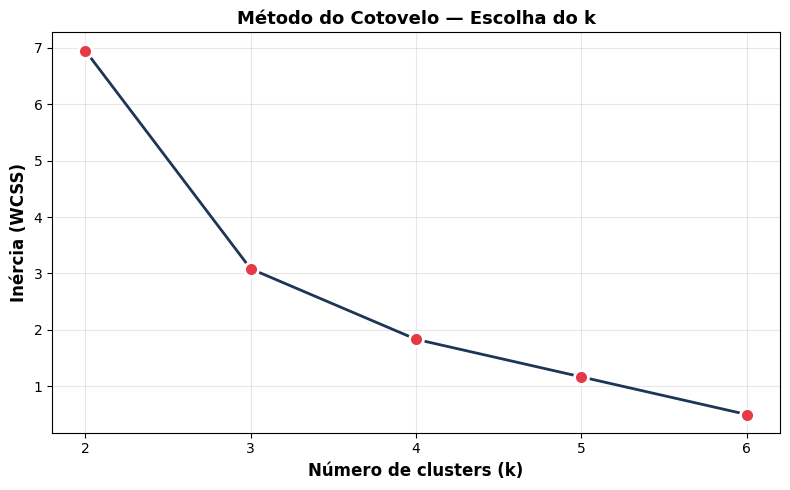

INÉRCIA POR K
k=2: 6.95
k=3: 3.08
k=4: 1.83
k=5: 1.17
k=6: 0.50


In [18]:
# ============================================================
# 4. MÉTODO DO COTOVELO
# ============================================================
inercias = []
K_range = range(2, 7)

for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_filmes)
    inercias.append(km.inertia_)

# Visualização
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(K_range, inercias, 'o-', color='#1D3557', linewidth=2, markersize=10,
        markerfacecolor='#E63946', markeredgecolor='white', markeredgewidth=2)
ax.set_xlabel('Número de clusters (k)', fontsize=12, fontweight='bold')
ax.set_ylabel('Inércia (WCSS)', fontsize=12, fontweight='bold')
ax.set_title('Método do Cotovelo — Escolha do k', fontsize=13, fontweight='bold')
ax.grid(alpha=0.3)
ax.set_xticks(list(K_range))
plt.tight_layout()
plt.savefig('cotovelo_filmes.png', dpi=120, bbox_inches='tight')
plt.show()

print("=" * 60)
print("INÉRCIA POR K")
print("=" * 60)
for k, inercia in zip(K_range, inercias):
    print(f"k={k}: {inercia:.2f}")

## **Aplicação do   K-MEANS (K=3)**

In [19]:
K = 3
km = KMeans(n_clusters=K, init='k-means++', n_init=25, random_state=42)
filmes['cluster'] = km.fit_predict(X_filmes)


print("Clusters de filmes")

for c in range(K):
    filmes_cluster = filmes[filmes['cluster'] == c]
    print(f"\n Cluster {c}:")
    for _, row in filmes_cluster.iterrows():
        generos = [g for g in features_cols if row[g] == 1]
        print(f"   {row['titulo']:25s} → {', '.join(generos)}")

Clusters de filmes

🎬 Cluster 0:
   Matrix                    → acao, drama, ficcao
   John Wick                 → acao
   Interestelar              → acao, drama, ficcao
   Vingadores                → acao, ficcao

🎬 Cluster 1:
   Titanic                   → drama, romance
   O Poderoso Chefão         → drama
   La La Land                → drama, romance

🎬 Cluster 2:
   Toy Story                 → comedia, animacao
   Shrek                     → comedia, animacao
   Se Beber Não Case         → comedia
